In [1]:
import pandas as pd
import matplotlib.pyplot as plt

market = pd.read_csv("../data/Market_Prices_Cleaned.csv")
route = pd.read_csv("../data/Route_Details_Cleaned.csv")
shipment = pd.read_csv("../data/Shipment_Details_Cleaned.csv")

print("Market Dataset:", market.shape)
print("Route Dataset:", route.shape)
print("Shipment Dataset:", shipment.shape)

Market Dataset: (2000, 8)
Route Dataset: (60, 6)
Shipment Dataset: (500, 10)


In [2]:
print("MARKET COLUMNS")
print(market.columns.tolist())

print("\nROUTE COLUMNS")
print(route.columns.tolist())

print("\nSHIPMENT COLUMNS")
print(shipment.columns.tolist())

MARKET COLUMNS
['Price_ID', 'Date', 'City', 'State', 'Product', 'Minimum_Price_Per_KG', 'Maximum_Price_Per_KG', 'Modal_Price_Per_KG']

ROUTE COLUMNS
['Route_ID', 'Origin_City', 'Destination_City', 'Distance_KM', 'Estimated_Travel_Hours', 'Transport_Cost_Per_KM']

SHIPMENT COLUMNS
['Shipment_ID', 'Container_ID', 'Product', 'Quantity_KG', 'Origin_City', 'Destination_City', 'Dispatch_Date', 'Expected_Arrival_Date', 'Transport_Mode', 'Transport_Cost']


In [3]:
market["Date"] = pd.to_datetime(market["Date"])

shipment["Dispatch_Date"] = pd.to_datetime(shipment["Dispatch_Date"])

print("MARKET DATE RANGE:")
print(market["Date"].min(), "to", market["Date"].max())

print("\nSHIPMENT DATE RANGE:")
print(shipment["Dispatch_Date"].min(), "to", shipment["Dispatch_Date"].max())

print("\nMARKET CITIES:")
print(sorted(market["City"].dropna().unique()))

print("\nROUTE CITIES:")
print(sorted(set(route["Origin_City"]) | set(route["Destination_City"])))

MARKET DATE RANGE:
2025-01-01 00:00:00 to 2025-12-31 00:00:00

SHIPMENT DATE RANGE:
2025-01-01 06:00:00 to 2025-12-31 17:00:00

MARKET CITIES:
['Ahmedabad', 'Bengaluru', 'Chennai', 'Delhi', 'Hyderabad', 'Kochi', 'Kolkata', 'Mumbai', 'Nagpur', 'Pune', 'Tirupati', 'Vijayawada']

ROUTE CITIES:
['Ahmedabad', 'Bengaluru', 'Chennai', 'Delhi', 'Hyderabad', 'Kochi', 'Kolkata', 'Mumbai', 'Nagpur', 'Pune', 'Tirupati', 'Vijayawada']


In [4]:
print("Total Market Records:", len(market))

print(
    "Unique Dates:",
    market["Date"].nunique()
)

print(
    "Unique Products:",
    market["Product"].nunique()
)

print(
    "Unique Cities:",
    market["City"].nunique()
)

print(
    "Missing Market Prices:",
    market["Modal_Price_Per_KG"].isnull().sum()
)

Total Market Records: 2000
Unique Dates: 364
Unique Products: 5
Unique Cities: 12
Missing Market Prices: 0


In [5]:
market_pivot = market.pivot_table(
    index=["Date", "Product"],
    columns="City",
    values="Modal_Price_Per_KG",
    aggfunc="mean"
)

valid_comparisons = market_pivot.dropna(thresh=2)

print("Total Date-Product Combinations:", len(market_pivot))

print("Combinations with at least 2 cities:",
      len(valid_comparisons))

print("\nProduct-wise Valid Comparisons:")

print(
    valid_comparisons.notna().sum(axis=1)
    .groupby("Product")
    .count()
)

Total Date-Product Combinations: 1212
Combinations with at least 2 cities: 522

Product-wise Valid Comparisons:
Product
Avocados    113
Bananas     123
Grapes       81
Mangoes     101
Tomatoes    104
dtype: int64


In [6]:
route_duplicates = route.groupby(
    ["Origin_City", "Destination_City"]
).size().reset_index(name="Record_Count")

route_duplicates = route_duplicates[
    route_duplicates["Record_Count"] > 1
]

display(route_duplicates)

,Origin_City,Destination_City,Record_Count
23,Hyderabad,Nagpur,2
41,Nagpur,Hyderabad,2


In [7]:
duplicate_route_details = route[
    (
        (route["Origin_City"] == "Hyderabad") &
        (route["Destination_City"] == "Nagpur")
    ) |
    (
        (route["Origin_City"] == "Nagpur") &
        (route["Destination_City"] == "Hyderabad")
    )
]

display(
    duplicate_route_details.sort_values(
        by=["Origin_City", "Destination_City"]
    )
)

,Route_ID,Origin_City,Destination_City,Distance_KM,Estimated_Travel_Hours,Transport_Cost_Per_KM
4,R005,Hyderabad,Nagpur,500,13.7,29.60
59,R060,Hyderabad,Nagpur,500,13.7,18.03
29,R030,Nagpur,Hyderabad,500,13.7,18.03
34,R035,Nagpur,Hyderabad,500,13.7,29.60


In [8]:
route["Estimated_Route_Cost"] = (
    route["Distance_KM"] *
    route["Transport_Cost_Per_KM"]
)

display(
    duplicate_route_details.assign(
        Estimated_Route_Cost=(
            duplicate_route_details["Distance_KM"] *
            duplicate_route_details["Transport_Cost_Per_KM"]
        )
    )
)

,Route_ID,Origin_City,Destination_City,Distance_KM,Estimated_Travel_Hours,Transport_Cost_Per_KM,Estimated_Route_Cost
4,R005,Hyderabad,Nagpur,500,13.7,29.60,14800.0
29,R030,Nagpur,Hyderabad,500,13.7,18.03,9015.0
34,R035,Nagpur,Hyderabad,500,13.7,29.60,14800.0
59,R060,Hyderabad,Nagpur,500,13.7,18.03,9015.0


In [9]:
route_cost_scenarios = route.groupby(
    ["Origin_City", "Destination_City"]
).agg(
    Minimum_Route_Cost=("Estimated_Route_Cost", "min"),
    Maximum_Route_Cost=("Estimated_Route_Cost", "max"),
    Route_Records=("Route_ID", "count")
).reset_index()

display(
    route_cost_scenarios.sort_values(
        by="Minimum_Route_Cost",
        ascending=False
    ).head(10).round(2)
)

,Origin_City,Destination_City,Minimum_Route_Cost,Maximum_Route_Cost,Route_Records
14,Chennai,Kolkata,49882.9,49882.9,1
30,Kolkata,Chennai,49882.9,49882.9,1
31,Kolkata,Delhi,43314.3,43314.3,1
18,Delhi,Kolkata,43314.3,43314.3,1
19,Delhi,Nagpur,30366.0,30366.0,1
40,Nagpur,Delhi,30366.0,30366.0,1
0,Ahmedabad,Delhi,28899.0,28899.0,1
17,Delhi,Ahmedabad,28899.0,28899.0,1
29,Kochi,Vijayawada,27450.0,27450.0,1
56,Vijayawada,Kochi,27450.0,27450.0,1


In [11]:
lowest_price = valid_comparisons.min(axis=1)
highest_price = valid_comparisons.max(axis=1)

same_day_arbitrage = pd.DataFrame({
    "Lowest_Price_City": valid_comparisons.idxmin(axis=1),
    "Lowest_Price": lowest_price,
    "Highest_Price_City": valid_comparisons.idxmax(axis=1),
    "Highest_Price": highest_price,
    "Potential_Price_Gap": highest_price - lowest_price
})

display(same_day_arbitrage.head())

Lowest_Price_City  Lowest_Price Highest_Price_City  \
Date       Product                                                       
2025-01-01 Grapes           Bengaluru         84.39           Tirupati   
           Mangoes             Mumbai         87.90               Pune   
2025-01-02 Avocados             Delhi        180.77            Kolkata   
           Bananas            Kolkata         32.85            Chennai   
           Grapes           Hyderabad         81.59           Tirupati   

                     Highest_Price  Potential_Price_Gap  
Date       Product                                       
2025-01-01 Grapes           102.32                17.93  
           Mangoes           94.26                 6.36  
2025-01-02 Avocados         219.97                39.20  
           Bananas           41.88                 9.03  
           Grapes            83.53                 1.94

In [12]:
arbitrage_candidates = same_day_arbitrage.reset_index()

arbitrage_route_analysis = pd.merge(
    arbitrage_candidates,
    route_cost_scenarios,
    left_on=["Lowest_Price_City", "Highest_Price_City"],
    right_on=["Origin_City", "Destination_City"],
    how="left"
)

print("Total Price Opportunities:", len(arbitrage_route_analysis))

print(
    "Opportunities with Route Available:",
    arbitrage_route_analysis["Minimum_Route_Cost"].notna().sum()
)

print(
    "Opportunities without Route:",
    arbitrage_route_analysis["Minimum_Route_Cost"].isna().sum()
)

display(arbitrage_route_analysis.head(10).round(2))

Total Price Opportunities: 522
Opportunities with Route Available: 212
Opportunities without Route: 310


C:\Users\sanga\AppData\Local\Temp\ipykernel_2044\787574211.py:23: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(arbitrage_route_analysis.head(10).round(2))


,Date,Product,Lowest_Price_City,Lowest_Price,Highest_Price_City,Highest_Price,Potential_Price_Gap,Origin_City,Destination_City,Minimum_Route_Cost,Maximum_Route_Cost,Route_Records
0,2025-01-01,Grapes,Bengaluru,84.39,Tirupati,102.32,17.93,Bengaluru,Tirupati,4965.0,4965.0,1.0
1,2025-01-01,Mangoes,Mumbai,87.90,Pune,94.26,6.36,Mumbai,Pune,4495.5,4495.5,1.0
2,2025-01-02,Avocados,Delhi,180.77,Kolkata,219.97,39.20,Delhi,Kolkata,43314.3,43314.3,1.0
3,2025-01-02,Bananas,Kolkata,32.85,Chennai,41.88,9.03,Kolkata,Chennai,49882.9,49882.9,1.0
4,2025-01-02,Grapes,Hyderabad,81.59,Tirupati,83.53,1.94,Hyderabad,Tirupati,12476.8,12476.8,1.0
5,2025-01-03,Bananas,Pune,30.26,Kochi,39.63,9.37,NaN,NaN,NaN,NaN,NaN
6,2025-01-03,Tomatoes,Pune,24.00,Vijayawada,26.48,2.48,NaN,NaN,NaN,NaN,NaN
7,2025-01-04,Avocados,Chennai,177.72,Kochi,197.32,19.60,Chennai,Kochi,21176.1,21176.1,1.0
8,2025-01-04,Tomatoes,Kochi,27.77,Nagpur,30.44,2.67,NaN,NaN,NaN,NaN,NaN
9,2025-01-05,Bananas,Mumbai,32.54,Ahmedabad,33.97,1.43,Mumbai,Ahmedabad,16207.4,16207.4,1.0


In [13]:
shipment["Transport_Cost_Per_KG"] = (
    shipment["Transport_Cost"] /
    shipment["Quantity_KG"]
)

shipment_route_cost = shipment.groupby(
    ["Origin_City", "Destination_City"]
).agg(
    Average_Transport_Cost_Per_KG=(
        "Transport_Cost_Per_KG", "mean"
    ),
    Total_Shipments=("Shipment_ID", "count")
).reset_index()

display(
    shipment_route_cost.head(10).round(4)
)

,Origin_City,Destination_City,Average_Transport_Cost_Per_KG,Total_Shipments
0,Ahmedabad,Delhi,3.0661,8
1,Ahmedabad,Mumbai,1.6677,7
2,Ahmedabad,Nagpur,1.4404,6
3,Ahmedabad,Pune,1.7246,7
4,Bengaluru,Chennai,0.8074,8
5,Bengaluru,Hyderabad,1.3433,10
6,Bengaluru,Kochi,1.0532,5
7,Bengaluru,Mumbai,2.2759,11
8,Bengaluru,Pune,1.7274,10
9,Bengaluru,Tirupati,0.5230,12


In [14]:
arbitrage_final = pd.merge(
    arbitrage_route_analysis,
    shipment_route_cost,
    on=["Origin_City", "Destination_City"],
    how="left"
)

arbitrage_final["Estimated_Gross_Margin_Per_KG"] = (
    arbitrage_final["Potential_Price_Gap"]
    - arbitrage_final["Average_Transport_Cost_Per_KG"]
)

print("Total Opportunities:", len(arbitrage_final))

print(
    "Opportunities with Shipment Cost:",
    arbitrage_final["Average_Transport_Cost_Per_KG"].notna().sum()
)

print(
    "Opportunities without Shipment Cost:",
    arbitrage_final["Average_Transport_Cost_Per_KG"].isna().sum()
)

display(
    arbitrage_final.head(15).round(2)
)

Total Opportunities: 522
Opportunities with Shipment Cost: 212
Opportunities without Shipment Cost: 310


C:\Users\sanga\AppData\Local\Temp\ipykernel_2044\4001308155.py:26: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  arbitrage_final.head(15).round(2)


,Date,Product,Lowest_Price_City,Lowest_Price,Highest_Price_City,Highest_Price,Potential_Price_Gap,Origin_City,Destination_City,Minimum_Route_Cost,Maximum_Route_Cost,Route_Records,Average_Transport_Cost_Per_KG,Total_Shipments,Estimated_Gross_Margin_Per_KG
0,2025-01-01,Grapes,Bengaluru,84.39,Tirupati,102.32,17.93,Bengaluru,Tirupati,4965.0,4965.0,1.0,0.52,12.0,17.41
1,2025-01-01,Mangoes,Mumbai,87.90,Pune,94.26,6.36,Mumbai,Pune,4495.5,4495.5,1.0,0.46,9.0,5.90
2,2025-01-02,Avocados,Delhi,180.77,Kolkata,219.97,39.20,Delhi,Kolkata,43314.3,43314.3,1.0,4.32,9.0,34.88
3,2025-01-02,Bananas,Kolkata,32.85,Chennai,41.88,9.03,Kolkata,Chennai,49882.9,49882.9,1.0,5.08,8.0,3.95
4,2025-01-02,Grapes,Hyderabad,81.59,Tirupati,83.53,1.94,Hyderabad,Tirupati,12476.8,12476.8,1.0,1.27,15.0,0.67
5,2025-01-03,Bananas,Pune,30.26,Kochi,39.63,9.37,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,2025-01-03,Tomatoes,Pune,24.00,Vijayawada,26.48,2.48,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,2025-01-04,Avocados,Chennai,177.72,Kochi,197.32,19.60,Chennai,Kochi,21176.1,21176.1,1.0,2.20,6.0,17.40
8,2025-01-04,Tomatoes,Kochi,27.77,Nagpur,30.44,2.67,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,2025-01-05,Bananas,Mumbai,32.54,Ahmedabad,33.97,1.43,Mumbai,Ahmedabad,16207.4,16207.4,1.0,1.70,10.0,-0.27


In [15]:
valid_arbitrage = arbitrage_final.dropna(
    subset=["Estimated_Gross_Margin_Per_KG"]
)

print("Total Valid Opportunities:", len(valid_arbitrage))

print(
    "Positive Margin Opportunities:",
    (valid_arbitrage["Estimated_Gross_Margin_Per_KG"] > 0).sum()
)

print(
    "Negative Margin Opportunities:",
    (valid_arbitrage["Estimated_Gross_Margin_Per_KG"] < 0).sum()
)

print(
    "Zero Margin Opportunities:",
    (valid_arbitrage["Estimated_Gross_Margin_Per_KG"] == 0).sum()
)

print("\nOVERALL MARGIN STATISTICS")

display(
    valid_arbitrage[
        ["Potential_Price_Gap",
         "Average_Transport_Cost_Per_KG",
         "Estimated_Gross_Margin_Per_KG"]
    ].describe().round(2)
)

Total Valid Opportunities: 212
Positive Margin Opportunities: 193
Negative Margin Opportunities: 19
Zero Margin Opportunities: 0

OVERALL MARGIN STATISTICS


,Potential_Price_Gap,Average_Transport_Cost_Per_KG,Estimated_Gross_Margin_Per_KG
count,212.00,212.00,212.00
mean,13.46,1.85,11.61
std,13.81,1.07,13.82
min,0.02,0.39,-3.15
25%,4.10,1.27,2.26
50%,8.60,1.68,6.70
75%,19.10,2.27,17.40
max,83.59,5.33,81.16


In [16]:
product_arbitrage_summary = valid_arbitrage.groupby(
    "Product"
).agg(
    Total_Opportunities=("Product", "count"),
    Average_Price_Gap=("Potential_Price_Gap", "mean"),
    Average_Transport_Cost=(
        "Average_Transport_Cost_Per_KG", "mean"
    ),
    Average_Gross_Margin=(
        "Estimated_Gross_Margin_Per_KG", "mean"
    ),
    Positive_Opportunities=(
        "Estimated_Gross_Margin_Per_KG",
        lambda x: (x > 0).sum()
    )
).round(2)

display(product_arbitrage_summary)

,Total_Opportunities,Average_Price_Gap,Average_Transport_Cost,Average_Gross_Margin,Positive_Opportunities
Product,,,,,
Avocados,52,27.88,1.96,25.92,51
Bananas,41,4.72,1.79,2.93,34
Grapes,31,11.18,1.49,9.68,30
Mangoes,41,15.26,1.94,13.32,39
Tomatoes,47,5.08,1.94,3.13,39


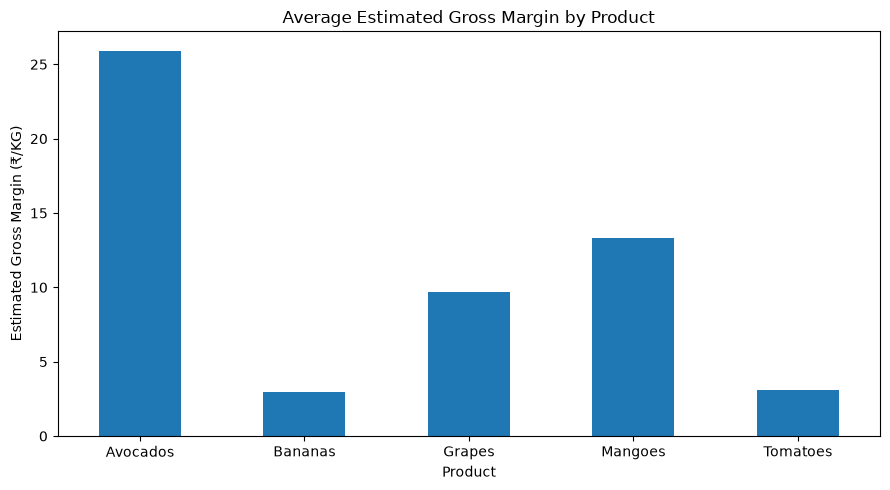

In [17]:
product_arbitrage_summary["Average_Gross_Margin"].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Average Estimated Gross Margin by Product")
plt.xlabel("Product")
plt.ylabel("Estimated Gross Margin (₹/KG)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

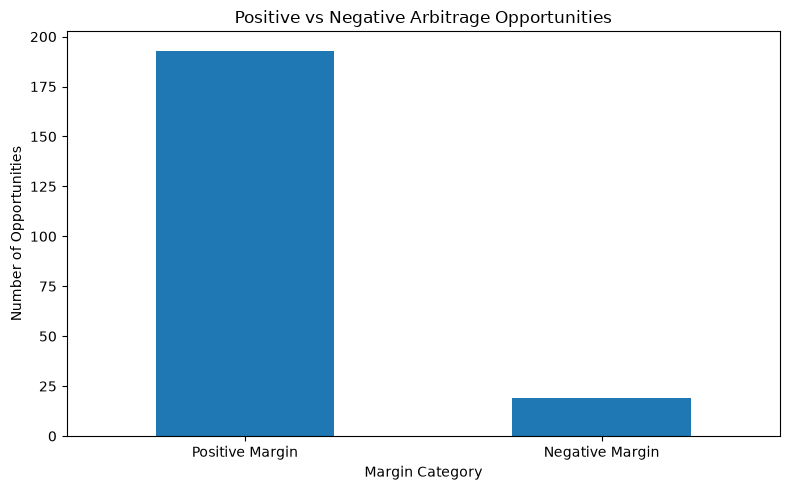

In [18]:
margin_counts = pd.Series({
    "Positive Margin": (
        valid_arbitrage["Estimated_Gross_Margin_Per_KG"] > 0
    ).sum(),
    "Negative Margin": (
        valid_arbitrage["Estimated_Gross_Margin_Per_KG"] < 0
    ).sum()
})

margin_counts.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Positive vs Negative Arbitrage Opportunities")
plt.xlabel("Margin Category")
plt.ylabel("Number of Opportunities")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [19]:
import os

os.makedirs("../outputs", exist_ok=True)

# Save all 522 price-gap opportunities
arbitrage_final.to_csv(
    "../outputs/arbitrage_all_opportunities.csv",
    index=False
)

# Save 212 opportunities with transport cost and margin
valid_arbitrage.to_csv(
    "../outputs/arbitrage_valid_opportunities.csv",
    index=False
)

# Save product-wise summary
product_arbitrage_summary.to_csv(
    "../outputs/product_arbitrage_summary.csv"
)

# Save route cost scenarios
route_cost_scenarios.to_csv(
    "../outputs/route_cost_scenarios.csv",
    index=False
)

print("All arbitrage analysis files exported successfully!")

All arbitrage analysis files exported successfully!


In [20]:
top_10_margins = valid_arbitrage.sort_values(
    by="Estimated_Gross_Margin_Per_KG",
    ascending=False
).head(10)

top_10_margins[
    [
        "Date",
        "Product",
        "Lowest_Price_City",
        "Highest_Price_City",
        "Potential_Price_Gap",
        "Average_Transport_Cost_Per_KG",
        "Estimated_Gross_Margin_Per_KG"
    ]
].round(2)

C:\Users\sanga\AppData\Local\Temp\ipykernel_2044\2011103895.py:16: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2)


,Date,Product,Lowest_Price_City,Highest_Price_City,Potential_Price_Gap,Average_Transport_Cost_Per_KG,Estimated_Gross_Margin_Per_KG
129,2025-03-23,Avocados,Vijayawada,Kolkata,83.59,2.43,81.16
140,2025-03-27,Avocados,Pune,Ahmedabad,67.90,1.68,66.22
513,2025-12-27,Avocados,Hyderabad,Chennai,60.40,1.35,59.05
41,2025-01-24,Avocados,Kolkata,Nagpur,57.84,2.04,55.80
203,2025-05-14,Avocados,Bengaluru,Vijayawada,56.61,1.89,54.72
21,2025-01-11,Avocados,Chennai,Kolkata,56.73,5.33,51.40
463,2025-11-24,Avocados,Mumbai,Bengaluru,48.39,2.27,46.12
375,2025-09-19,Avocados,Mumbai,Ahmedabad,45.21,1.70,43.51
86,2025-02-20,Mangoes,Pune,Mumbai,39.92,0.44,39.48
382,2025-09-26,Avocados,Mumbai,Hyderabad,40.42,1.46,38.96


In [21]:
top_10_margins.to_csv(
    "../outputs/top_10_arbitrage_opportunities.csv",
    index=False
)

print("Top 10 arbitrage opportunities saved successfully!")

Top 10 arbitrage opportunities saved successfully!


In [22]:
print("===== ATMOSYNC ARBITRAGE ANALYSIS =====")

print("Total Price Opportunities:", len(arbitrage_final))
print("Opportunities with Cost Data:", len(valid_arbitrage))

print(
    "Positive Margin Opportunities:",
    (valid_arbitrage["Estimated_Gross_Margin_Per_KG"] > 0).sum()
)

print(
    "Negative Margin Opportunities:",
    (valid_arbitrage["Estimated_Gross_Margin_Per_KG"] < 0).sum()
)

print(
    "Average Price Gap:",
    round(valid_arbitrage["Potential_Price_Gap"].mean(), 2)
)

print(
    "Average Transport Cost per KG:",
    round(valid_arbitrage["Average_Transport_Cost_Per_KG"].mean(), 2)
)

print(
    "Average Estimated Gross Margin per KG:",
    round(valid_arbitrage["Estimated_Gross_Margin_Per_KG"].mean(), 2)
)

print(
    "Highest Estimated Gross Margin per KG:",
    round(valid_arbitrage["Estimated_Gross_Margin_Per_KG"].max(), 2)
)

===== ATMOSYNC ARBITRAGE ANALYSIS =====
Total Price Opportunities: 522
Opportunities with Cost Data: 212
Positive Margin Opportunities: 193
Negative Margin Opportunities: 19
Average Price Gap: 13.46
Average Transport Cost per KG: 1.85
Average Estimated Gross Margin per KG: 11.61
Highest Estimated Gross Margin per KG: 81.16


In [23]:
final_findings = pd.DataFrame({
    "Metric": [
        "Total Price Opportunities",
        "Opportunities with Cost Data",
        "Positive Margin Opportunities",
        "Negative Margin Opportunities",
        "Average Price Gap (INR/KG)",
        "Average Transport Cost (INR/KG)",
        "Average Estimated Gross Margin (INR/KG)",
        "Highest Estimated Gross Margin (INR/KG)"
    ],
    "Value": [
        len(arbitrage_final),
        len(valid_arbitrage),
        (valid_arbitrage["Estimated_Gross_Margin_Per_KG"] > 0).sum(),
        (valid_arbitrage["Estimated_Gross_Margin_Per_KG"] < 0).sum(),
        round(valid_arbitrage["Potential_Price_Gap"].mean(), 2),
        round(valid_arbitrage["Average_Transport_Cost_Per_KG"].mean(), 2),
        round(valid_arbitrage["Estimated_Gross_Margin_Per_KG"].mean(), 2),
        round(valid_arbitrage["Estimated_Gross_Margin_Per_KG"].max(), 2)
    ]
})

final_findings.to_csv(
    "../outputs/final_arbitrage_findings.csv",
    index=False
)

final_findings

,Metric,Value
0,Total Price Opportunities,522.00
1,Opportunities with Cost Data,212.00
2,Positive Margin Opportunities,193.00
3,Negative Margin Opportunities,19.00
4,Average Price Gap (INR/KG),13.46
5,Average Transport Cost (INR/KG),1.85
6,Average Estimated Gross Margin (INR/KG),11.61
7,Highest Estimated Gross Margin (INR/KG),81.16


In [24]:
final_findings.style.format({
    "Value": lambda x: f"{x:,.2f}" if x % 1 else f"{x:,.0f}"
}).hide(axis="index")

Metric,Value
Total Price Opportunities,522
Opportunities with Cost Data,212
Positive Margin Opportunities,193
Negative Margin Opportunities,19
Average Price Gap (INR/KG),13.46
Average Transport Cost (INR/KG),1.85
Average Estimated Gross Margin (INR/KG),11.61
Highest Estimated Gross Margin (INR/KG),81.16
